# ¿A quién llamar primero? Modelo de propensión para campañas bancarias

**Pregunta de negocio:** un banco hace campañas telefónicas para vender depósitos a plazo. Llamar a todos los clientes es caro y la tasa de conversión es baja. ¿Podemos ordenar a los clientes según su probabilidad de aceptar la oferta para conseguir más ventas con menos llamadas?

**Datos:** [Bank Marketing (UCI)](https://archive.ics.uci.edu/dataset/222/bank+marketing), campañas de un banco portugués (2008–2010). Licencia CC BY 4.0.

**Contenido**
1. Carga de datos
2. Exploración
3. Preparación (y por qué se elimina `duration`)
4. Modelos y evaluación
5. Valor de negocio: curva de ganancia y análisis costo-beneficio
6. Lista priorizada de contactos

In [1]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PALETA = ["#6B2D8C", "#7A1F3D", "#B23A6A", "#D9C2E8"]
sns.set_theme(style="whitegrid", palette=PALETA)
RANDOM_STATE = 42

DATA_DIR = Path("data/raw")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

## 1. Carga de datos
El notebook descarga el archivo la primera vez. Si la descarga falla, baja el zip desde la página del dataset y coloca `bank-additional-full.csv` en `data/raw/`.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
CSV = DATA_DIR / "bank-additional-full.csv"


def descargar_datos():
    if CSV.exists():
        return
    print("Descargando Bank Marketing desde UCI...")
    with urllib.request.urlopen(URL) as r:
        externo = zipfile.ZipFile(io.BytesIO(r.read()))
    nombre_interno = next(n for n in externo.namelist() if n.endswith("bank-additional.zip"))
    interno = zipfile.ZipFile(io.BytesIO(externo.read(nombre_interno)))
    miembro = next(n for n in interno.namelist() if n.endswith("bank-additional-full.csv"))
    CSV.write_bytes(interno.read(miembro))


descargar_datos()
df = pd.read_csv(CSV, sep=";")
print(df.shape)
df.head()

Descargando Bank Marketing desde UCI...
(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Exploración

Tasa de conversión global: 11.3%


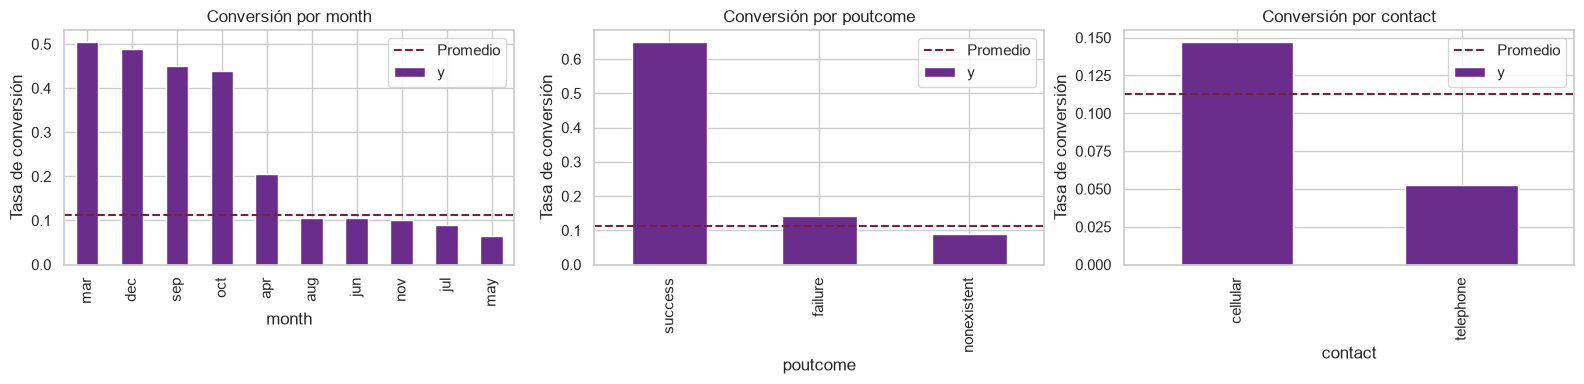

In [3]:
tasa_global = (df["y"] == "yes").mean()
print(f"Tasa de conversión global: {tasa_global:.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["month", "poutcome", "contact"]):
    tasa = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    tasa.plot.bar(ax=ax, color=PALETA[0])
    ax.axhline(tasa_global, color=PALETA[1], ls="--", label="Promedio")
    ax.set_title(f"Conversión por {col}")
    ax.set_ylabel("Tasa de conversión")
    ax.legend()
plt.tight_layout()
plt.show()

**Lectura:** los clientes que aceptaron en una campaña anterior (`poutcome = success`) convierten muchas veces más que el promedio, y algunos meses rinden más que otros. El modelo aprovechará estas señales.

## 3. Preparación
- **Se elimina `duration`** (duración de la llamada): solo se conoce después de llamar, así que usarla para decidir a quién llamar sería hacer trampa (fuga de información).
- `pdays = 999` significa "nunca contactado antes"; lo convertimos en una variable binaria.

In [4]:
datos = df.drop(columns=["duration"]).copy()
datos["contactado_antes"] = (datos["pdays"] != 999).astype(int)
datos = datos.drop(columns=["pdays"])

y = (datos.pop("y") == "yes").astype(int)
X = datos

cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

## 4. Modelos y evaluación
Comparamos un modelo interpretable (regresión logística) con uno más flexible (gradient boosting). Como solo ~11 % de los clientes convierte, además del ROC AUC miramos el **PR AUC**, más exigente con clases desbalanceadas.

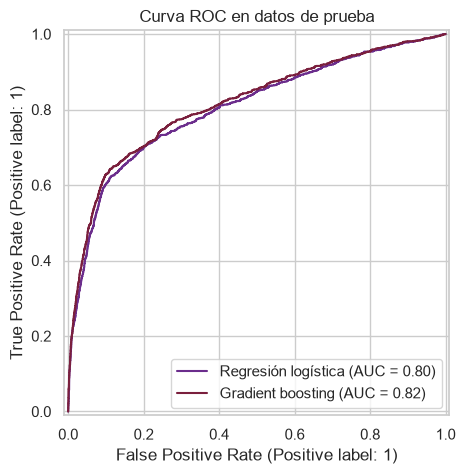

,ROC AUC,PR AUC
Modelo,,
Regresión logística,0.805,0.463
Gradient boosting,0.815,0.492


In [5]:
modelos = {
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE
    ),
}

entrenados, resultados = {}, []
fig, ax = plt.subplots(figsize=(6, 5))
for nombre, modelo in modelos.items():
    pipe = Pipeline([("pre", clone(preprocesador)), ("modelo", modelo)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    entrenados[nombre] = pipe
    resultados.append({
        "Modelo": nombre,
        "ROC AUC": roc_auc_score(y_test, p),
        "PR AUC": average_precision_score(y_test, p),
    })
    RocCurveDisplay.from_predictions(y_test, p, name=nombre, ax=ax)
ax.set_title("Curva ROC en datos de prueba")
plt.show()

resultados = pd.DataFrame(resultados).set_index("Modelo").round(3)
resultados

In [6]:
mejor_nombre = resultados["PR AUC"].idxmax()
mejor = entrenados[mejor_nombre]
score = mejor.predict_proba(X_test)[:, 1]
print("Modelo elegido:", mejor_nombre)

Modelo elegido: Gradient boosting


## 5. Valor de negocio
### Tabla por deciles y curva de ganancia
Ordenamos a los clientes de prueba de mayor a menor probabilidad y los dividimos en 10 grupos iguales.

In [9]:

def tabla_deciles(y_real, score):
    # Creamos el DataFrame inicial
    d = pd.DataFrame({"y": np.asarray(y_real), "score": score})
    
    # --- CORRECCIÓN: Cortamos por la columna 'score', no por el índice ---
    # Usamos labels=range(10, 0, -1) para que el decil 1 sea el de mayor score
    d["decil"] = pd.qcut(d["score"], 10, labels=range(10, 0, -1))
    
    # Agrupamos por decil
    t = d.groupby("decil", observed=True).agg(
        clientes=("y", "size"), 
        conversiones=("y", "sum")
    )
    
    # Calculamos las métricas
    t["tasa_conversion"] = t["conversiones"] / t["clientes"]
    t["lift"] = t["tasa_conversion"] / d["y"].mean()
    t["% conversiones acumuladas"] = t["conversiones"].cumsum() / t["conversiones"].sum()
    
    return t

# Uso de la función
deciles = tabla_deciles(y_test, score)
deciles.style.format({
    "tasa_conversion": "{:.1%}", 
    "lift": "{:.2f}", 
    "% conversiones acumuladas": "{:.1%}"
})


,clientes,conversiones,tasa_conversion,lift,% conversiones acumuladas
decil,,,,,
10,1030,24,2.3%,0.21,2.1%
9,1030,35,3.4%,0.30,5.1%
8,1032,36,3.5%,0.31,8.2%
7,1027,45,4.4%,0.39,12.1%
6,1030,45,4.4%,0.39,15.9%
5,1029,57,5.5%,0.49,20.9%
4,1030,57,5.5%,0.49,25.8%
3,1029,91,8.8%,0.79,33.6%
2,1030,216,21.0%,1.86,52.2%


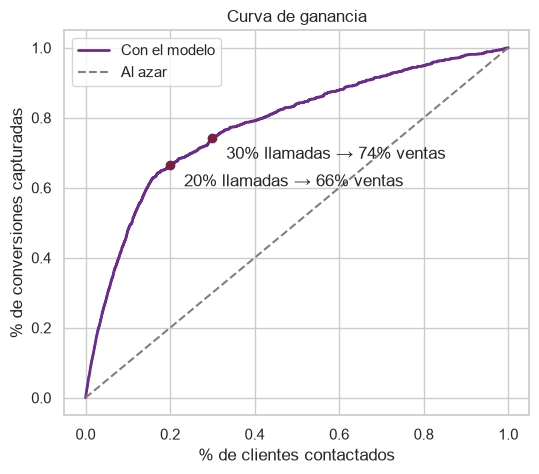

In [10]:
orden = np.argsort(-score)
y_ordenado = np.asarray(y_test)[orden]
pct_contactado = np.arange(1, len(y_ordenado) + 1) / len(y_ordenado)
pct_capturado = np.cumsum(y_ordenado) / y_ordenado.sum()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(pct_contactado, pct_capturado, color=PALETA[0], lw=2, label="Con el modelo")
ax.plot([0, 1], [0, 1], color="gray", ls="--", label="Al azar")
for corte in (0.2, 0.3):
    capt = pct_capturado[int(corte * len(pct_capturado)) - 1]
    ax.scatter(corte, capt, color=PALETA[1], zorder=3)
    ax.annotate(f"{corte:.0%} llamadas → {capt:.0%} ventas", (corte, capt),
                textcoords="offset points", xytext=(10, -15))
ax.set_xlabel("% de clientes contactados")
ax.set_ylabel("% de conversiones capturadas")
ax.set_title("Curva de ganancia")
ax.legend()
plt.show()

### Análisis costo-beneficio
Con supuestos **ilustrativos** (ajústalos a la realidad de cada negocio): cada llamada cuesta 5 y cada depósito vendido deja un margen de 100. ¿Hasta qué punto de la lista conviene llamar?

Llamar a todos: beneficio = 64,515
Llamar al 34% con mayor probabilidad: beneficio = 72,040
Llamadas evitadas: 6,765


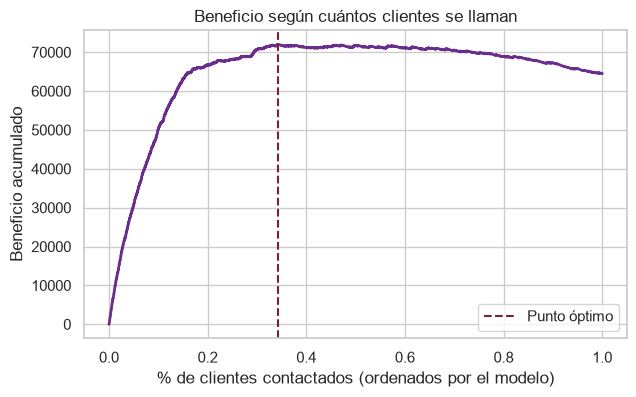

In [11]:
COSTO_LLAMADA = 5        # supuesto ilustrativo
MARGEN_CONVERSION = 100  # supuesto ilustrativo

llamadas = np.arange(1, len(y_ordenado) + 1)
beneficio = np.cumsum(y_ordenado) * MARGEN_CONVERSION - llamadas * COSTO_LLAMADA
i_opt = int(np.argmax(beneficio))
beneficio_todos = y_ordenado.sum() * MARGEN_CONVERSION - len(y_ordenado) * COSTO_LLAMADA

print(f"Llamar a todos: beneficio = {beneficio_todos:,.0f}")
print(f"Llamar al {pct_contactado[i_opt]:.0%} con mayor probabilidad: beneficio = {beneficio[i_opt]:,.0f}")
print(f"Llamadas evitadas: {len(y_ordenado) - (i_opt + 1):,}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pct_contactado, beneficio, color=PALETA[0], lw=2)
ax.axvline(pct_contactado[i_opt], color=PALETA[1], ls="--", label="Punto óptimo")
ax.set_xlabel("% de clientes contactados (ordenados por el modelo)")
ax.set_ylabel("Beneficio acumulado")
ax.set_title("Beneficio según cuántos clientes se llaman")
ax.legend()
plt.show()

## 6. Lista priorizada
Exportamos a los clientes de prueba ordenados por probabilidad, listos para que el equipo comercial los contacte en ese orden.

In [12]:
lista = X_test.copy()
lista["probabilidad"] = score
lista = lista.sort_values("probabilidad", ascending=False)
lista["prioridad"] = pd.qcut(lista["probabilidad"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lista.to_csv(OUT_DIR / "lista_priorizada.csv", index=False)
lista.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,contactado_antes,probabilidad,prioridad
39655,92,retired,married,unknown,no,yes,no,cellular,may,thu,...,2,success,-1.8,93.876,-40.0,0.683,5008.7,1,0.861012,1
40469,92,retired,married,unknown,no,no,yes,cellular,aug,wed,...,4,success,-1.7,94.027,-38.3,0.903,4991.6,1,0.857240,1
39498,80,retired,divorced,basic.4y,no,yes,yes,cellular,apr,thu,...,2,success,-1.8,93.749,-34.6,0.644,5008.7,1,0.851574,1
39650,77,retired,married,university.degree,no,yes,no,telephone,may,wed,...,4,success,-1.8,93.876,-40.0,0.682,5008.7,1,0.849812,1
39676,76,retired,married,basic.4y,no,yes,no,cellular,may,fri,...,2,success,-1.8,93.876,-40.0,0.684,5008.7,1,0.848530,1
40450,92,retired,married,unknown,no,no,yes,cellular,aug,tue,...,1,success,-1.7,94.027,-38.3,0.904,4991.6,1,0.847748,1
39348,78,retired,married,unknown,no,no,no,cellular,mar,thu,...,2,success,-1.8,93.369,-34.8,0.635,5008.7,1,0.846018,1
40686,83,retired,divorced,basic.4y,no,no,no,cellular,sep,thu,...,3,success,-1.1,94.199,-37.5,0.879,4963.6,1,0.836452,1
39221,34,admin.,single,university.degree,no,no,no,cellular,mar,tue,...,1,success,-1.8,93.369,-34.8,0.652,5008.7,1,0.835716,1
39607,52,admin.,married,university.degree,no,no,no,cellular,may,thu,...,2,success,-1.8,93.876,-40.0,0.677,5008.7,1,0.834923,1


## Conclusiones
- El modelo ordena a los clientes de forma que los primeros deciles concentran una proporción de ventas muy superior al azar (ver *lift* y curva de ganancia).
- Con los supuestos de costo usados, llamar solo a una parte de la lista da más beneficio que llamar a todos.
- Siguientes pasos: probar en una campaña real con grupo de control (A/B) y recalibrar con datos recientes.